# 03 · Artigo 2 — projeto multi-cenário (Costa, Tonassi & Souza, 2016)

**Hydraulic design optimization of multi-scenario of cooling water distribution system**,
*Chemical Engineering Transactions* 52, 2016.

A mesma rede do Artigo 1 deve operar em quatro cenários de vazão (Tabela 3) com válvulas de
controle em cada circuito. O MILP do artigo (binárias para a escolha da bomba) é resolvido
aqui como um LP por alternativa de bomba (equivalente): variáveis `X_{p,n}` e
`y_{h,sc}`; restrições (1)-(3) replicadas por cenário. Preço da energia 0.05 USD/kWh;
método tradicional de Towler & Sinnott com o maior diâmetro entre os cenários.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cwnet import load_case, run_design_study
from cwnet.reporting import plots, tables

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
CASES = Path("../cases")

In [2]:
case = load_case(CASES / "paper2_multiscenario.yaml")
print(case.name); print(case.description)

Paper 2 - multi-scenario design of the cooling water network
20 nodes, 23 edges, 5 heat exchangers, 4 operating scenarios with control valves


## Figura 1 — rede exemplo

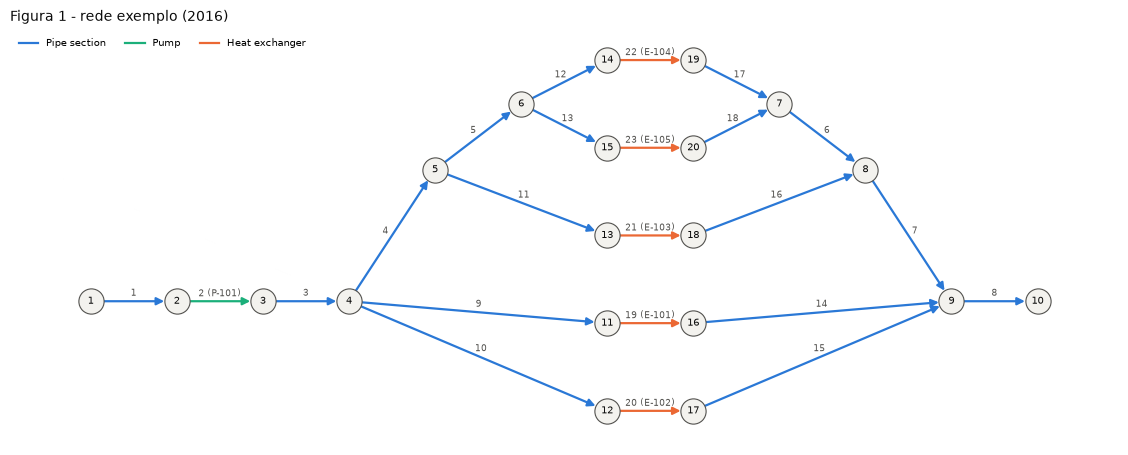

In [3]:
ax = plots.plot_digraph(case, title="Figura 1 - rede exemplo (2016)")

## Tabelas 1-4 — dados

In [4]:
print("Tabela 1 - comprimentos"); display(tables.pipe_lengths_table(case))
print("Tabela 2 - diâmetros"); display(tables.pipe_catalog_table(case))
print("Tabela 3 - vazões por cenário e condição de projeto"); display(tables.scenario_table(case))
print("Tabela 4 - curvas das bombas"); display(tables.pump_catalog_table(case))
print("fator de anualização r = %.3f" % case.economics.annualizing_factor)

Tabela 1 - comprimentos


,Pipe section,Length (m)
0,1,10.0
1,"9, 10, 11, 13, 14, 15, 16, 18",25.0
2,"4, 5, 6, 7",100.0
3,"12, 17",125.0
4,"3, 8",200.0


Tabela 2 - diâmetros


,Nominal diameter (in),Inner diameter (mm),Outer diameter (mm)
0,1/2,15.8,21.3
1,3/4,21.0,26.7
2,1,26.6,33.4
3,1 1/4,35.1,42.2
4,1 1/2,40.9,48.3
5,2,52.5,60.3
6,2 1/2,62.7,73.0
7,3,77.9,88.9
8,3 1/2,90.1,101.6
9,4,102.3,114.3


Tabela 3 - vazões por cenário e condição de projeto


,Heat exchanger,Scenario 1 (kg/s),Scenario 2 (kg/s),Scenario 3 (kg/s),Scenario 4 (kg/s),Design (kg/s),Design head loss (m)
0,E-101,11.8,12.4,11.80,11.8,12.4,5.53
1,E-102,28.7,30.1,0.01,28.7,30.1,6.35
2,E-103,35.6,37.4,0.01,37.4,37.4,4.82
3,E-104,15.6,15.6,15.60,16.4,16.4,2.97
4,E-105,3.1,3.1,3.10,3.2,3.2,1.20


Tabela 4 - curvas das bombas


,Alternative,a2 (s2/m5),a1 (s/m2),a0 (m),Efficiency,Rated flow (m3/s)
0,Pump 0,-83.12,-27.0,6.3,0.6,0.095276
1,Pump 1,-415.60,-135.0,31.5,0.6,0.095276
2,Pump 2,-498.70,-162.0,37.8,0.6,0.095276
3,Pump 3,-554.10,-180.0,42.0,0.6,0.095276
4,Pump 4,-609.50,-198.0,46.2,0.6,0.095276


fator de anualização r = 0.134


## Otimização

A bomba 0 (6.3 m de head) não consegue vencer a perda de carga dos trocadores mais os 5 m
de elevação: o seu LP é inviável e é reportado como tal. Ambas as abordagens escolhem a
bomba 1, como no artigo.

In [5]:
study = run_design_study(case)
display(tables.cost_comparison_table(study))
print("melhor:", study.best.label, "| tradicional:", study.traditional["towler"].design.pump_curve)

,Methodology / case,Pump,Total cost (USD/y),Operational cost (USD/y),Pump cost (USD/y),Pipe cost (USD),Feasible
0,Traditional (towler),Pump 1,15431.0,9576.0,3051.0,20941.0,True
1,Proposed / Pump 0,Pump 0,NaN,NaN,NaN,NaN,False
2,Proposed / Pump 1,Pump 1,14364.0,8968.0,3051.0,17512.0,True
3,Proposed / Pump 2,Pump 2,16018.0,10762.0,3217.0,15240.0,True
4,Proposed / Pump 3,Pump 3,17205.0,11986.0,3319.0,14190.0,True
5,Proposed / Pump 4,Pump 4,18439.0,13190.0,3417.0,13682.0,True


melhor: Proposed / Pump 1 | tradicional: Pump 1


## Tabela 5 — diâmetros (otimização × tradicional)

Como nos demais casos, o LP tem ótimos alternativos (degenerados): a solução publicada
coloca 48.4 % de 10" na tubulação 1; aqui o mesmo comprimento de 10" pode aparecer na
tubulação 8 do mesmo coletor. O custo de tubos é o mesmo (Tabela 7).

In [6]:
PUBLISHED_T5 = {1: ("10 (48.4%) / 12 (51.6%)", "14"), 3: ("12", "14"), 4: ("8 (34.2%) / 10 (65.8%)", "10"),
    5: ("6", "6"), 6: ("6", "6"), 7: ("8", "10"), 8: ("12", "14"), 9: ("3 1/2", "5"), 10: ("6", "8"), 11: ("8", "8"),
    12: ("6", "6"), 13: ("1 1/2 (20%) / 2 (80%)", "2 1/2"), 14: ("3 1/2 (2.4%) / 4 (97.6%)", "5"), 15: ("6", "8"),
    16: ("6 (24.4%) / 8 (75.6%)", "8"), 17: ("6", "6"), 18: ("2", "2 1/2")}
tbl = tables.design_comparison_table(study, traditional="towler")
tbl["Published optimization"] = [PUBLISHED_T5[e][0] for e in tbl["Edge"]]
tbl["Published traditional"] = [PUBLISHED_T5[e][1] for e in tbl["Edge"]]
display(tbl)

,Edge,Traditional diameter (in),Optimization diameter (in),Optimization length fraction,Published optimization,Published traditional
0,1,14,12,1.000,10 (48.4%) / 12 (51.6%),14
1,3,14,12,1.000,12,14
2,4,10,8/10,0.346/0.654,8 (34.2%) / 10 (65.8%),10
3,5,6,6,1.000,6,6
4,6,6,6,1.000,6,6
5,7,10,8,1.000,8,10
6,8,14,10/12,0.026/0.974,12,14
7,9,5,3 1/2,1.000,3 1/2,5
8,10,8,6,1.000,6,8
9,11,8,8,1.000,8,8


## Tabela 6 — perdas de carga nas válvulas por cenário

In [7]:
PUBLISHED_T6 = pd.DataFrame({"Heat exchanger": ["E-101", "E-102", "E-103", "E-104", "E-105"],
    "Published S1": [1.58, 1.55, 1.52, 1.33, 1.21], "Published S2": [0.00, 0.00, 0.00, 0.25, 0.13],
    "Published S3": [15.3, 21.75, 21.52, 16.56, 16.44], "Published S4": [0.89, 0.91, 0.22, 0.00, 0.00]})
display(tables.valve_table(study.best, case).merge(PUBLISHED_T6, on="Heat exchanger"))

,Heat exchanger,Scenario 1 (m),Scenario 2 (m),Scenario 3 (m),Scenario 4 (m),Published S1,Published S2,Published S3,Published S4
0,E-101,1.579,0.000,15.283,0.894,1.58,0.00,15.30,0.89
1,E-102,1.551,0.000,21.752,0.867,1.55,0.00,21.75,0.91
2,E-103,1.523,0.000,21.515,0.223,1.52,0.00,21.52,0.22
3,E-104,1.326,0.247,16.563,0.000,1.33,0.25,16.56,0.00
4,E-105,1.206,0.126,16.443,0.000,1.21,0.13,16.44,0.00


As válvulas dependem do vértice degenerado escolhido (um pouco mais de perda num tubo
implica um pouco menos numa válvula do mesmo circuito), por isso os valores dos cenários 1,
2 e 4 podem diferir ligeiramente dos publicados; no cenário 3 (E-102 e E-103 fora de
serviço) as válvulas absorvem ~15-22 m, como no artigo.

## Tabelas 7, 9 e 10 — custos

O artigo reporta *pump capital costs* = 3 051 $; esse valor é o custo anualizado
`r·C_PU` (com FMS = 1.3). Na Tabela 10 o total anualizado foi obtido como
`operacional + r·(tubos + 3 051)`, ou seja, o custo da bomba foi anualizado duas vezes.
A célula seguinte mostra os componentes calculados, a aritmética do artigo e a aritmética
consistente (`objective_basis: annualized`).

In [8]:
best, trad = study.best, study.traditional["towler"]
r = case.economics.annualizing_factor
rows = []
for label, ev, pub in (("Optimization approach", best, (17516, 3051, 8959, 11712)),
                       ("Traditional approach", trad, (20941, 3051, 9605, 12818))):
    c = ev.costs
    rows.append({"Item": label,
                 "Pipe capital (USD)": round(c.pipe_capital), "published": pub[0],
                 "r x pump capital (USD/y)": round(c.pump_capital_annualized), "published ": pub[1],
                 "Operating (USD/y)": round(c.operating), "published  ": pub[2],
                 "Total, paper arithmetic (USD/y)": round(c.operating + r * (c.pipe_capital + c.pump_capital_annualized)),
                 "published   ": pub[3],
                 "Total, consistent (USD/y)": round(c.total_annualized)})
display(pd.DataFrame(rows))
print("redução de custo total (aritmética consistente): %.1f %%" % (100 * (1 - best.costs.total_annualized / trad.costs.total_annualized)))

,Item,Pipe capital (USD),published,r x pump capital (USD/y),published,Operating (USD/y),published,"Total, paper arithmetic (USD/y)",published,"Total, consistent (USD/y)"
0,Optimization approach,17512,17516,3051,3051,8968,8959,11721,11712,14364
1,Traditional approach,20941,20941,3051,3051,9576,9605,12788,12818,15431


redução de custo total (aritmética consistente): 6.9 %


## Tabela 8 — vazões simuladas com o projeto tradicional (sem válvulas)

In [9]:
PUBLISHED_T8 = {"E-101": 13.2, "E-102": 30.1, "E-103": 39.6, "E-104": 16.4, "E-105": 4.6}
tab = tables.network_behaviour_table(trad)
tab["Published simulated flow (kg/s)"] = [PUBLISHED_T8.get(t, round(sum(PUBLISHED_T8.values()), 1)) for t in tab["Heat exchanger"]]
display(tab)

,Heat exchanger,Design flow (kg/s),Simulated flow (kg/s),Published simulated flow (kg/s)
0,0,11.8,13.17,103.9
1,1,28.7,30.12,103.9
2,2,35.6,39.57,103.9
3,3,15.6,16.48,103.9
4,4,3.1,4.58,103.9
5,Total,94.8,103.92,103.9


## Verificação: com as válvulas, a rede otimizada entrega as vazões de cada cenário

In [10]:
display(tables.exchanger_flows_by_scenario_table(best))
display(tables.pump_operating_table(study))
print("balanceada em todos os cenários:", best.hydraulically_balanced)

,Heat exchanger,Scenario 1 specified (kg/s),Scenario 1 simulated (kg/s),Scenario 2 specified (kg/s),Scenario 2 simulated (kg/s),Scenario 3 specified (kg/s),Scenario 3 simulated (kg/s),Scenario 4 specified (kg/s),Scenario 4 simulated (kg/s)
0,1,11.8,11.8,12.4,12.4,11.80,11.80,11.8,11.8
1,2,28.7,28.7,30.1,30.1,0.01,0.01,28.7,28.7
2,3,35.6,35.6,37.4,37.4,0.01,0.01,37.4,37.4
3,4,15.6,15.6,15.6,15.6,15.60,15.60,16.4,16.4
4,5,3.1,3.1,3.1,3.1,3.10,3.10,3.2,3.2


,Design,Scenario,Pump,Flow (kg/s),Head (m),Power (kW),Operating cost (USD/y),Converged
0,Traditional (towler),Scenario 1,Pump 1,103.92,12.868,21.86,9576,True
1,Traditional (towler),Scenario 2,Pump 1,103.92,12.868,21.86,9576,True
2,Traditional (towler),Scenario 3,Pump 1,103.92,12.868,21.86,9576,True
3,Traditional (towler),Scenario 4,Pump 1,103.92,12.868,21.86,9576,True
4,Proposed / Pump 1,Scenario 1,Pump 1,94.80,14.865,23.04,10092,True
5,Proposed / Pump 1,Scenario 2,Pump 1,98.60,14.041,22.64,9914,True
6,Proposed / Pump 1,Scenario 3,Pump 1,30.52,26.968,13.46,5894,True
7,Proposed / Pump 1,Scenario 4,Pump 1,97.50,14.281,22.77,9971,True
8,Proposed / Pump 2,Scenario 1,Pump 2,94.80,17.838,27.65,12110,True
9,Proposed / Pump 2,Scenario 2,Pump 2,98.60,16.849,27.16,11897,True


balanceada em todos os cenários: True


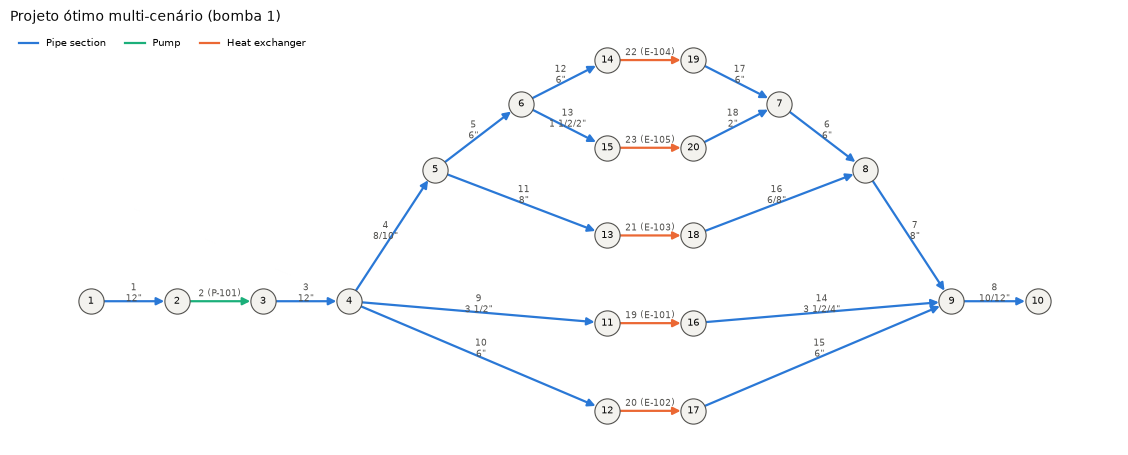

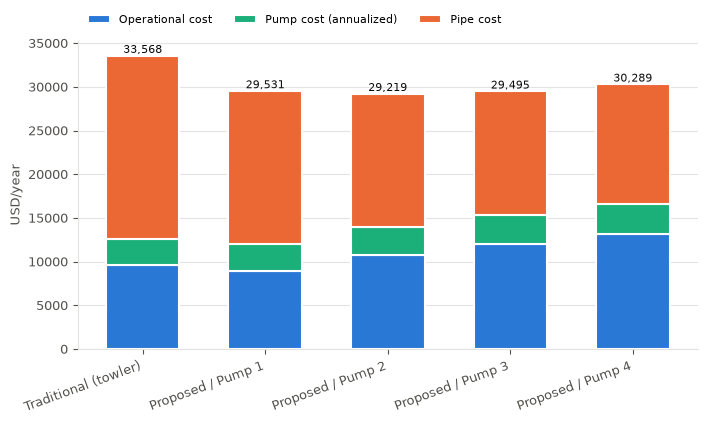

In [11]:
ax = plots.plot_digraph(case, design=best.design, title="Projeto ótimo multi-cenário (bomba 1)")
ax2 = plots.plot_cost_comparison(study, basis="annualized")